# Implicit recommendations with Spark MLlib

API notebook for the 13F recommender. The data here is a small
made-up set of managers and stocks, so the MLlib calls are easy to
read. The example
notebook is the one that uses the SEC filings.

- `StringIndexer` for managers and CUSIPs
- `ALS` with `implicitPrefs=True`
- `ParamGridBuilder` on `rank`, `regParam`, and `alpha`
- `recommendForAllUsers` and `RankingEvaluator`
- `KMeans` on the item factors

In [ ]:
%load_ext autoreload
%autoreload 2

import logging
import os
import sys

import pandas as pd
import pyspark.sql.functions as F
import seaborn as sns
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import RankingEvaluator
from pyspark.ml.feature import StringIndexer
from pyspark.ml.recommendation import ALS
from pyspark.ml.tuning import ParamGridBuilder

In [ ]:
# Find helpers_root whether this is opened from the project dir or the repo root.
_path = os.getcwd()
while not os.path.isdir(os.path.join(_path, "helpers_root", "helpers")):
    _parent = os.path.dirname(_path)
    if _parent == _path:
        break
    _path = _parent
sys.path.insert(0, os.path.join(_path, "helpers_root"))

import helpers.hnotebook as hnotebook

import mllib_utils as utils

hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > C:\Users\Sawyer Byrd\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\ipykernel_launcher.py --f="c:\Users\Sawyer Byrd\AppData\Roaming\jupyter\runtime\kernel-v3f941b56e9a0346b954d74f257411212979291c37.json"


## Toy ratings

Growth managers hold tech names and value managers hold bank names.
Each manager keeps 5 names in both quarters and opens 2 more in
December. Those 2 opens are the test items. `rating` is
$\log(1+\mathrm{value})$.

In [ ]:
TECH = ["AAPL", "MSFT", "NVDA", "GOOG", "AMZN", "META", "AVGO", "AMD"]
BANKS = ["JPM", "BAC", "GS", "WFC", "C", "MS", "BX", "SCHW"]
TRAIN = "2025-09-30"
TEST = "2025-12-31"


def _block(managers, stocks):
    # 5 names in both quarters, then 2 new names in December only.
    rows = []
    n_stocks = len(stocks)
    for i, manager in enumerate(managers):
        for offset in range(5):
            cusip = stocks[(i + offset) % n_stocks]
            rows.append((manager, cusip, TRAIN, 500.0))
            rows.append((manager, cusip, TEST, 500.0))
        for offset in (5, 6):
            cusip = stocks[(i + offset) % n_stocks]
            rows.append((manager, cusip, TEST, 800.0))
    return rows


spark = utils.build_spark()
rows = _block(["g1", "g2", "g3", "g4"], TECH)
rows += _block(["v1", "v2", "v3", "v4"], BANKS)
ratings = spark.createDataFrame(
    rows, ["manager", "cusip", "report_period", "value"]
)
ratings = ratings.withColumn("rating", F.log1p("value"))
display(ratings.orderBy("report_period", "manager", "cusip").limit(8).toPandas())

,manager,cusip,report_period,value,rating
0,g1,AAPL,2025-09-30,500.0,6.216606
1,g1,AMZN,2025-09-30,500.0,6.216606
2,g1,GOOG,2025-09-30,500.0,6.216606
3,g1,MSFT,2025-09-30,500.0,6.216606
4,g1,NVDA,2025-09-30,500.0,6.216606
5,g2,AMZN,2025-09-30,500.0,6.216606
6,g2,GOOG,2025-09-30,500.0,6.216606
7,g2,META,2025-09-30,500.0,6.216606


## StringIndexer

ALS wants numeric ids. Fitting on the whole frame gives both quarters
the same ids.

In [ ]:
manager_indexer = StringIndexer(
    inputCol="manager", outputCol="manager_idx", handleInvalid="keep"
)
cusip_indexer = StringIndexer(
    inputCol="cusip", outputCol="item_idx", handleInvalid="keep"
)
indexed = manager_indexer.fit(ratings).transform(ratings)
indexed = cusip_indexer.fit(indexed).transform(indexed)
id_map = (
    indexed.select(
        F.lit("manager").alias("column"),
        F.col("manager").alias("label"),
        F.col("manager_idx").cast("int").alias("id"),
    )
    .unionByName(
        indexed.select(
            F.lit("cusip").alias("column"),
            F.col("cusip").alias("label"),
            F.col("item_idx").cast("int").alias("id"),
        )
    )
    .distinct()
    .orderBy("column", "id")
)
display(id_map.toPandas())

,column,label,id
0,cusip,AMZN,0
1,cusip,C,1
2,cusip,GOOG,2
3,cusip,WFC,3
4,cusip,META,4
5,cusip,MS,5
6,cusip,AVGO,6
7,cusip,BX,7
8,cusip,GS,8
9,cusip,NVDA,9


## Implicit ALS

Fit on September only. With `implicitPrefs=True` the rating is a
confidence, $1 + \alpha \log(1+\mathrm{value})$, not a star rating.
Pairs that are missing from the frame are unobserved.

`rank` is 2 so the cluster plot later is the whole factor. `alpha` 40
is a strong confidence on this toy set. `numUserBlocks` is 2 because
the default of 10 is larger than the number of managers.

In [ ]:
train = indexed.filter(F.col("report_period") == TRAIN)
als = ALS(
    userCol="manager_idx",
    itemCol="item_idx",
    ratingCol="rating",
    implicitPrefs=True,
    coldStartStrategy="drop",
    nonnegative=False,
    rank=2,
    maxIter=15,
    regParam=0.1,
    alpha=40.0,
    numUserBlocks=2,
    numItemBlocks=2,
    seed=7,
)
model = als.fit(train)
print("users", model.userFactors.count(), "items", model.itemFactors.count())

users 8 items 16


## ParamGridBuilder

The builder only makes the list of settings. Each one is fit on
September and scored on the December opens.

`RankingEvaluator` wants an array of item ids per manager.
`recommendForAllUsers` returns that. `ALS.transform` returns one score
per row, so it is the wrong input for this metric.

In [ ]:
# Names held in December but not in September.
train_pairs = train.select(
    F.col("manager_idx").cast("int").alias("manager_idx"),
    F.col("item_idx").cast("int").alias("item_idx"),
)
test = indexed.filter(F.col("report_period") == TEST).select(
    F.col("manager_idx").cast("int").alias("manager_idx"),
    F.col("item_idx").cast("int").alias("item_idx"),
    "manager",
    "cusip",
)
held_out = test.join(train_pairs, ["manager_idx", "item_idx"], "left_anti")
labels = held_out.groupBy("manager_idx").agg(
    F.collect_set(F.col("item_idx").cast("double")).alias("true_items")
)


def score_lists(fitted):
    """Precision@10 and NDCG@10 for one fitted ALS model."""
    recs = fitted.recommendForAllUsers(10)
    preds = recs.select(
        F.col("manager_idx").cast("int").alias("manager_idx"),
        F.expr(
            "transform(recommendations.item_idx, x -> cast(x as double))"
        ).alias("pred_items"),
    )
    joined = labels.join(preds, "manager_idx")
    scores = {}
    for name in ("precisionAtK", "ndcgAtK"):
        evaluator = RankingEvaluator(
            predictionCol="pred_items",
            labelCol="true_items",
            metricName=name,
            k=10,
        )
        scores[name] = round(evaluator.evaluate(joined), 4)
    return scores


grid = (
    ParamGridBuilder()
    .addGrid(als.rank, [2, 4])
    .addGrid(als.regParam, [0.01, 0.1])
    .addGrid(als.alpha, [1.0, 40.0])
    .build()
)
grid_rows = []
for params in grid:
    candidate = als.fit(train, params)
    grid_rows.append(
        {
            "rank": params[als.rank],
            "reg_param": params[als.regParam],
            "alpha": params[als.alpha],
            **score_lists(candidate),
        }
    )
scores = pd.DataFrame(grid_rows).sort_values(
    ["ndcgAtK", "precisionAtK"], ascending=False
)
display(scores.reset_index(drop=True))

,rank,reg_param,alpha,precisionAtK,ndcgAtK
0,2,0.01,1.0,0.2000,0.4411
1,2,0.10,40.0,0.2000,0.4411
2,2,0.10,1.0,0.2000,0.4368
3,2,0.01,40.0,0.2000,0.4334
4,4,0.10,1.0,0.1750,0.3551
5,4,0.10,40.0,0.1625,0.3267
6,4,0.01,40.0,0.1625,0.3211
7,4,0.01,1.0,0.1375,0.2740


## Recommendations

Top 3 of the 10 names from the model above. The list can include
stocks the manager already holds. Only the December opens count as
hits.

A CUSIP that never shows up in training has no item factor, so ALS
cannot recommend it. Every test name here was already held by another
manager.

In [ ]:
recs = model.recommendForAllUsers(10)
flat = recs.select(
    F.col("manager_idx").cast("int").alias("manager_idx"),
    F.posexplode("recommendations").alias("rank0", "rec"),
)
flat = flat.select(
    "manager_idx",
    (F.col("rank0") + 1).alias("rank"),
    F.col("rec.item_idx").cast("int").alias("item_id"),
    F.round(F.col("rec.rating"), 3).alias("score"),
)
managers = indexed.select(
    F.col("manager_idx").cast("int").alias("manager_idx"), "manager"
).distinct()
items = indexed.select(
    F.col("item_idx").cast("int").alias("item_id"), "cusip"
).distinct()
top3 = (
    flat.filter(F.col("rank") <= 3)
    .join(managers, "manager_idx")
    .join(items, "item_id")
    .orderBy("manager", "rank")
    .select("manager", "rank", "cusip", "score")
)
display(top3.toPandas())
display(pd.DataFrame([score_lists(model)]))

,manager,rank,cusip,score
0,g1,1,GOOG,1.001
1,g1,2,AMZN,1.001
2,g1,3,META,1.000
3,g2,1,GOOG,0.999
4,g2,2,AMZN,0.999
5,g2,3,META,0.998
6,g3,1,GOOG,0.998
7,g3,2,AMZN,0.998
8,g3,3,META,0.998
9,g4,1,GOOG,1.001


,precisionAtK,ndcgAtK
0,0.2,0.4411


## KMeans on the item factors

`itemFactors` is one vector per stock. Two clusters should separate
the tech names from the bank names.

,cusip,cluster,factor_0,factor_1
0,AAPL,0,-0.866,-0.836
1,AMD,0,-0.836,-0.872
2,AMZN,0,-0.868,-0.859
3,AVGO,0,-0.853,-0.870
4,GOOG,0,-0.868,-0.859
5,META,0,-0.863,-0.864
6,MSFT,0,-0.871,-0.848
7,NVDA,0,-0.870,-0.855
8,BAC,1,0.854,-0.971
9,BX,1,0.857,-0.967


<Axes: xlabel='factor_0', ylabel='factor_1'>

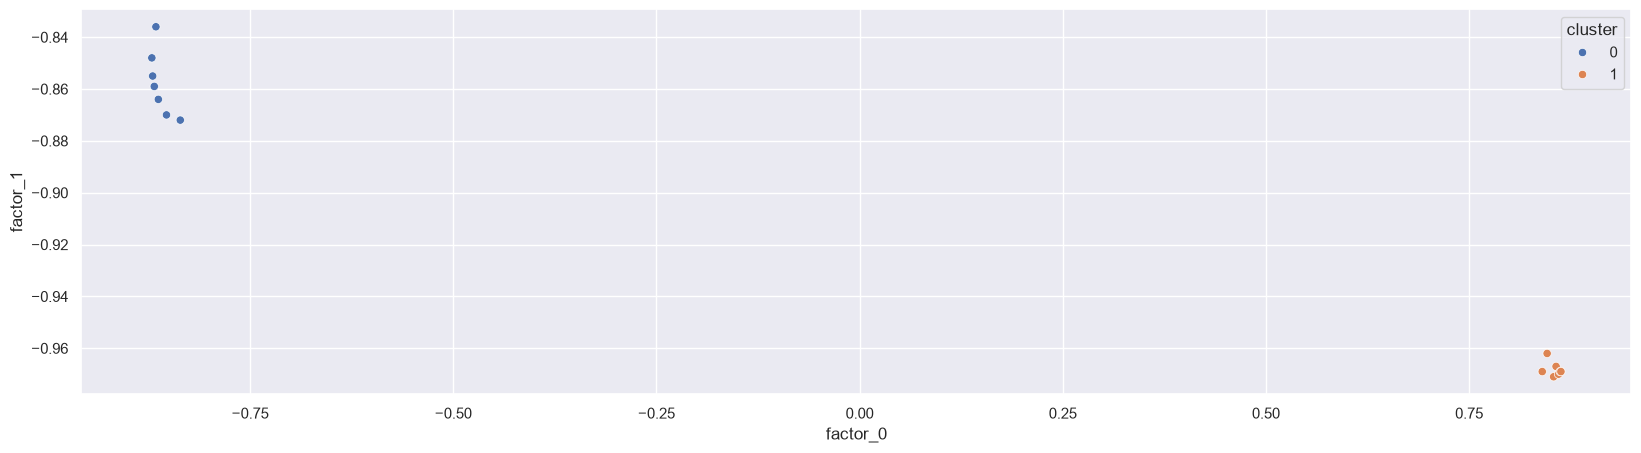

In [ ]:
factors = model.itemFactors
clustered = (
    KMeans(k=2, seed=7, featuresCol="features", predictionCol="cluster")
    .fit(factors)
    .transform(factors)
)
labeled = clustered.join(items.withColumnRenamed("item_id", "id"), "id")
table = labeled.select("cusip", "cluster", "features").toPandas()
table["factor_0"] = table["features"].apply(lambda v: round(float(v[0]), 3))
table["factor_1"] = table["features"].apply(lambda v: round(float(v[1]), 3))
table = table.drop(columns="features").sort_values(["cluster", "cusip"])
display(table.reset_index(drop=True))
sns.scatterplot(data=table, x="factor_0", y="factor_1", hue="cluster")